In [1]:
import matplotlib.pyplot as plt
import numpy as np
import os
import json

In [4]:
root = "datasets/TinyVIRAT-v2/TinyVIRAT_V2"
paths = os.listdir(root)
print(paths)

['tiny_test_v2_public.json', '.ipynb_checkpoints', 'tiny_val_v2.json', 'videos', 'changelog.txt', 'class_map.json', 'tiny_train_v2.json']


In [8]:
train_path = root + "/tiny_train_v2.json"

with open(train_path) as f:
    data = json.load(f)

In [1]:
import imageio
from ipywidgets import interact, IntSlider, FloatSlider


def video_from_imgs(image_stack, output_path, fps=2):
    fps = 5

    with imageio.get_writer(output_path, fps=fps) as vid:
        for frame in image_stack:
            if len(frame.shape) == 3:
                vid.append_data(frame[:,:,::-1])
            else:
                vid.append_data(frame)

ModuleNotFoundError: No module named 'ipywidgets'

In [14]:
from collections import defaultdict
import tqdm

d = defaultdict(int)
for el in data:
    d[tuple(el["dim"][1:])] += 1

print(d)

defaultdict(<class 'int'>, {(72, 72): 108, (114, 114): 200, (116, 116): 189, (102, 102): 136, (42, 42): 89, (128, 128): 327, (120, 120): 214, (108, 108): 122, (26, 26): 121, (46, 46): 181, (82, 82): 88, (62, 62): 68, (40, 40): 296, (106, 106): 148, (36, 36): 180, (50, 50): 166, (54, 54): 67, (70, 70): 153, (90, 90): 98, (112, 112): 7165, (118, 118): 187, (38, 38): 204, (80, 80): 62, (74, 74): 103, (84, 84): 110, (78, 78): 119, (58, 58): 149, (44, 44): 258, (66, 66): 175, (32, 32): 55, (94, 94): 123, (56, 56): 1667, (48, 48): 138, (30, 30): 94, (60, 60): 136, (88, 88): 86, (34, 34): 170, (28, 28): 126, (100, 100): 105, (92, 92): 66, (124, 124): 208, (104, 104): 145, (68, 68): 91, (24, 24): 141, (110, 110): 101, (8, 8): 7, (76, 76): 62, (96, 96): 71, (22, 22): 53, (18, 18): 35, (86, 86): 35, (52, 52): 139, (64, 64): 54, (20, 20): 20, (98, 98): 38, (122, 122): 214, (126, 126): 190, (14, 14): 34, (12, 12): 18, (16, 16): 9, (10, 10): 1, (111, 111): 93, (117, 117): 91, (125, 125): 161, (113,

In [16]:
print(len(data))

16950


In [19]:
cnt = 0
for el in d.items():
    cnt += el[1]

In [22]:
sorted([ (v, k) for k,v in d.items()])

[(1, (10, 10)),
 (7, (8, 8)),
 (9, (16, 16)),
 (18, (12, 12)),
 (20, (20, 20)),
 (23, (55, 55)),
 (34, (14, 14)),
 (35, (18, 18)),
 (35, (86, 86)),
 (38, (98, 98)),
 (53, (22, 22)),
 (54, (64, 64)),
 (55, (32, 32)),
 (62, (76, 76)),
 (62, (80, 80)),
 (66, (92, 92)),
 (67, (54, 54)),
 (68, (62, 62)),
 (71, (96, 96)),
 (86, (88, 88)),
 (86, (115, 115)),
 (88, (82, 82)),
 (89, (42, 42)),
 (91, (68, 68)),
 (91, (117, 117)),
 (93, (111, 111)),
 (94, (30, 30)),
 (98, (90, 90)),
 (100, (119, 119)),
 (101, (110, 110)),
 (101, (123, 123)),
 (103, (74, 74)),
 (105, (100, 100)),
 (108, (72, 72)),
 (110, (84, 84)),
 (119, (78, 78)),
 (121, (26, 26)),
 (122, (108, 108)),
 (122, (127, 127)),
 (123, (94, 94)),
 (123, (113, 113)),
 (126, (28, 28)),
 (135, (121, 121)),
 (136, (60, 60)),
 (136, (102, 102)),
 (138, (48, 48)),
 (139, (52, 52)),
 (141, (24, 24)),
 (145, (104, 104)),
 (148, (106, 106)),
 (149, (58, 58)),
 (153, (70, 70)),
 (161, (125, 125)),
 (166, (50, 50)),
 (170, (34, 34)),
 (175, (66, 6

In [33]:
for el in data:
    if tuple(el['dim'][1:]) == (112, 112):
        print(el['path'])
        break

VIRAT_S_050000_05_000696_000732/000028.mp4


# Classes

In [26]:
labels = []
for el in data:
    labels += el["label"]

['Closing' 'Entering' 'Exiting' 'Interacts' 'Loading' 'Misc' 'Opening'
 'Pull' 'Push' 'Riding' 'Talking' 'Transport_HeavyCarry'
 'activity_carrying' 'activity_gesturing' 'activity_running'
 'activity_standing' 'activity_walking' 'specialized_miscellaneous'
 'specialized_talking_phone' 'specialized_texting_phone'
 'specialized_using_tool' 'vehicle_moving' 'vehicle_starting'
 'vehicle_stopping' 'vehicle_turning_left' 'vehicle_turning_right']


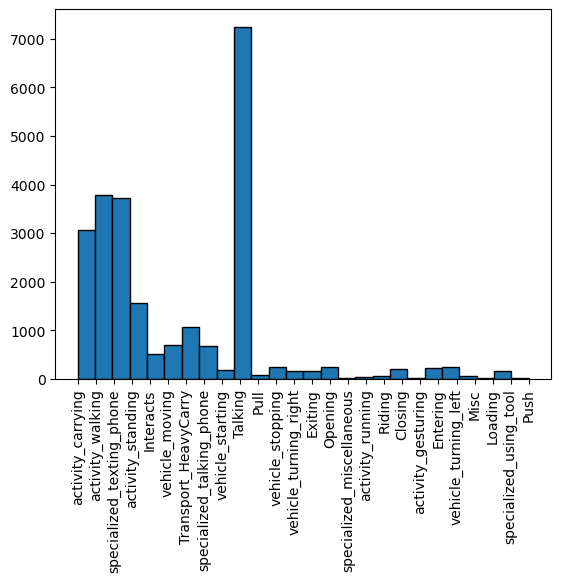

In [32]:
import matplotlib.pyplot as plt
uniques = np.unique(labels)
print(uniques)
plt.hist(labels, edgecolor="black", bins=len(uniques))
plt.xticks(rotation=90)
plt.show()